In [26]:
import pandas as pd
import matplotlib.pyplot as plt

In [12]:
sales=pd.read_csv('data/sales_clean.csv',parse_dates=['InvoiceDate'])  

In [13]:
is_product=sales['StockCode'].astype(str).str[0].str.isdigit()
products= sales[is_product]

In [14]:
product_revenue = products.groupby('StockCode').agg(Description=('Description', 'last'), Revenue=('Revenue', 'sum'))
product_revenue.sort_values('Revenue', ascending=False).head(10)

,Description,Revenue
StockCode,,
22423,REGENCY CAKESTAND 3 TIER,330590.32
85123A,CREAM HANGING HEART T-LIGHT HOLDER,261168.73
85099B,JUMBO BAG RED RETROSPOT,182680.98
47566,PARTY BUNTING,148318.28
84879,ASSORTED COLOUR BIRD ORNAMENT,129324.49
22086,PAPER CHAIN KIT 50'S CHRISTMAS,117760.29
79321,CHILLI LIGHTS,80540.88
22197,POPCORN HOLDER,79520.20
22386,JUMBO BAG PINK POLKADOT,76324.62


In [16]:
product_revenue['Revenue'].sum()


np.float64(19397038.95)

In [17]:
products['Revenue'].sum()

np.float64(19397038.950000003)

In [18]:
sales

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.40
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.00
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.00
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.80
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.00
...,...,...,...,...,...,...,...,...,...
1007905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,12.60
1007906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60
1007907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60
1007908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France,14.85


In [21]:
sales['Month']= sales['InvoiceDate'].dt.to_period('M')
sales.head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue,Month
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.4,2009-12
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0,2009-12
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0,2009-12
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.8,2009-12
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0,2009-12
5,489434,22064,PINK DOUGHNUT TRINKET POT,24,2009-12-01 07:45:00,1.65,13085.0,United Kingdom,39.6,2009-12
6,489434,21871,SAVE THE PLANET MUG,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0,2009-12
7,489434,21523,FANCY FONT HOME SWEET HOME DOORMAT,10,2009-12-01 07:45:00,5.95,13085.0,United Kingdom,59.5,2009-12
8,489435,22350,CAT BOWL,12,2009-12-01 07:46:00,2.55,13085.0,United Kingdom,30.6,2009-12
9,489435,22349,"DOG BOWL , CHASING BALL DESIGN",12,2009-12-01 07:46:00,3.75,13085.0,United Kingdom,45.0,2009-12


In [25]:
full_months=sales[sales['InvoiceDate']<'2011-12-01']
monthly_revenue = full_months.groupby("Month")['Revenue'].sum()

monthly_revenue.sort_values(ascending=False)

Month
2011-11    1503866.780
2010-11    1464293.142
2010-10    1161902.220
2011-10    1151263.730
2011-09    1056435.192
2010-09     921696.991
2010-03     830915.261
2009-12     822483.950
2010-12     821452.730
2011-05     769296.610
2011-06     760547.010
2010-06     749537.310
2011-08     746779.320
2011-07     718076.121
2011-03     716215.260
2010-08     695251.910
2010-04     678875.252
2010-05     657705.500
2010-01     651155.112
2010-07     648810.270
2011-01     612628.010
2010-02     551504.726
2011-04     536968.491
2011-02     522545.560
Freq: M, Name: Revenue, dtype: float64

In [24]:
sales['InvoiceDate'].max()

Timestamp('2011-12-09 12:50:00')

Text(0, 0.5, 'Revenue(£)')

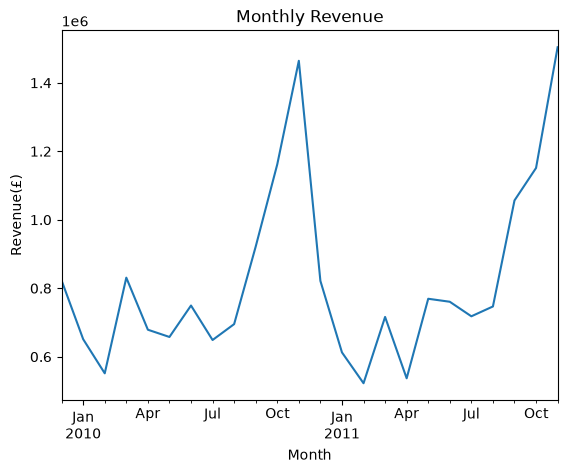

In [27]:

monthly_revenue.plot(kind='line')
plt.title('Monthly Revenue')
plt.xlabel('Month')
plt.ylabel('Revenue(£)')